In [46]:
%pip install -r requirements.txt


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## Libraries

In [47]:
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.callbacks import EarlyStopping
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

# Visualization
import matplotlib.pyplot as plt

# TensorFlow and Keras
from tensorflow.keras.layers import (
    Input,
    Dense,
    Dropout,
    Conv2D,
    MaxPooling2D,
    Flatten
)

## Data uploading

In [48]:
train_df = pd.read_csv("fashion-mnist_train.csv")
test_df = pd.read_csv("fashion-mnist_test.csv")

## Exploration

In [49]:
print("size of training", train_df.shape)
train_df.head()

size of training (60000, 785)


,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,6,0,0,0,0,0,0,0,5,0,...,0,0,0,30,43,0,0,0,0,0
3,0,0,0,0,1,2,0,0,0,0,...,3,0,0,0,0,1,0,0,0,0
4,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [50]:
print("size of training", test_df.shape)
test_df.head()

size of training (10000, 785)


,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,0,0,0,0,0,0,0,0,9,8,...,103,87,56,0,0,0,0,0,0,0
1,1,0,0,0,0,0,0,0,0,0,...,34,0,0,0,0,0,0,0,0,0
2,2,0,0,0,0,0,0,14,53,99,...,0,0,0,0,63,53,31,0,0,0
3,2,0,0,0,0,0,0,0,0,0,...,137,126,140,0,133,224,222,56,0,0
4,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [51]:
# Missing or null values
print("\nNull values in training: ", train_df.isnull().sum().sum())
print("Null values in test: ", test_df.isnull().sum().sum())


Null values in training:  0
Null values in test:  0


In [52]:
class_names = {
    0: "T-shirt/top",
    1: "Trouser",
    2: "Pullover",
    3: "Dress",
    4: "Coat",
    5: "Sandal",
    6: "Shirt",
    7: "Sneaker",
    8: "Bag",
    9: "Ankle boot"
}

train_dist = train_df["label"].value_counts().sort_index().rename(index=class_names)
test_dist = test_df["label"].value_counts().sort_index().rename(index=class_names)

class_summary = pd.DataFrame({
    "Train Count": train_dist,
    "Train (%)": (train_dist / len(train_df) * 100).round(2),
    "Test Count": test_dist,
    "Test (%)": (test_dist / len(test_df) * 100).round(2)
})

display(class_summary)

,Train Count,Train (%),Test Count,Test (%)
label,,,,
T-shirt/top,6000,10.0,1000,10.0
Trouser,6000,10.0,1000,10.0
Pullover,6000,10.0,1000,10.0
Dress,6000,10.0,1000,10.0
Coat,6000,10.0,1000,10.0
Sandal,6000,10.0,1000,10.0
Shirt,6000,10.0,1000,10.0
Sneaker,6000,10.0,1000,10.0
Bag,6000,10.0,1000,10.0


## Visualization

A representative of each class is shown

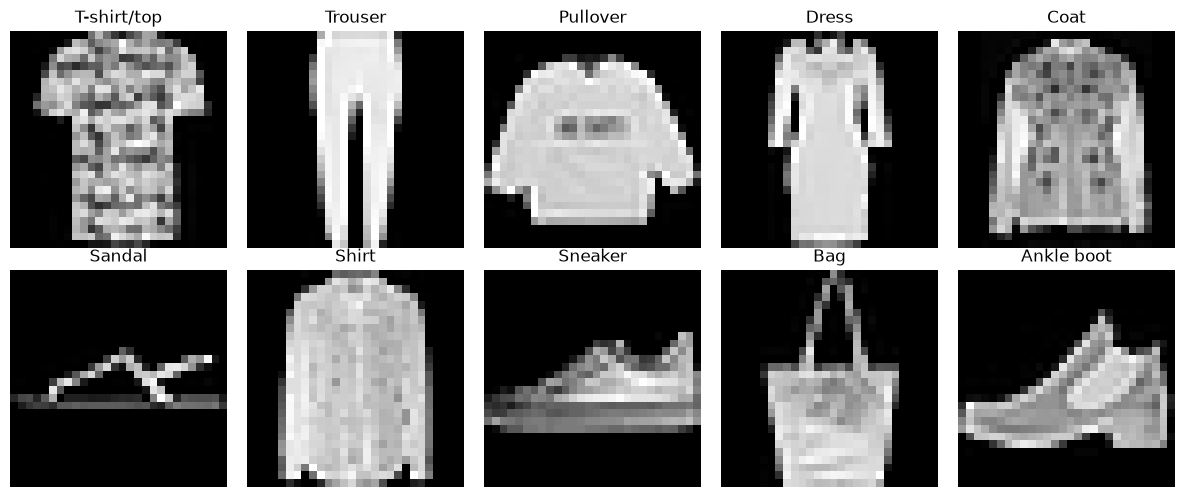

In [53]:
# Plot one sample image for each of the 10 clothing categories
plt.figure(figsize=(12, 5))

for label_id, class_name in class_names.items():
    sample_row = train_df[train_df["label"] == label_id].iloc[0]
    
    # Extract the 784 pixel values and reshape into a 28x28 image
    image_2d = sample_row.drop("label").values.reshape(28, 28)
    
    plt.subplot(2, 5, label_id + 1)
    plt.imshow(image_2d, cmap="gray")
    plt.title(class_name)
    plt.axis("off")

plt.tight_layout()
plt.show()

## Normalization

Each pixel value in the images is an integer between 0 and 255, neural networks tend to work harder as these numbers become bigger. In order to reduce the workload a normalization was applied, in other words each pixel is divided by 255 so we can obtain a value between 0 and 1.

In [54]:
# Separate the pixels and target labels (separating the images from the answers)
X_train_full = train_df.drop("label", axis=1).values
y_train_full = train_df["label"].values

X_test = test_df.drop("label", axis=1).values
y_test = test_df["label"].values

#Normalize pixel values from [0, 255] to [0, 1]
X_train_full = X_train_full.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

## Training, validation, and test sets

In [55]:
# Split training set (60,000 images) into 85% train (51,000) and validation (9,000), keeping test untouched

X_train_mlp, X_val_mlp, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.15,
    random_state=7,
    stratify=y_train_full # makes sure that the class distribution is equal in both train and validation sets
)

X_test_mlp = X_test  # Shape (10000, 784)

## Prepare the input dimensions required for the MLP and CNN models.

A CNN is a neural network designed to see and understand images, in comparison to an MLP neural network that checks every pixel and tries to find patterns, CNN applies different kinds of filter so that each layer detects different things, such as edges, curves or textures.

In order for CNN to work the pixels are reshaped as a 28 x 28 x 1 grid, where the 28 x 28 corresponds to the length and width of the picture, while the 1 represents the scale of grays from the image.

In [56]:
# Reshaping the data for CNN input
X_train_cnn = X_train_mlp.reshape(-1, 28, 28, 1) # -1 divides the number of samples by 784, resulting in n number of 28x28 images
X_val_cnn = X_val_mlp.reshape(-1, 28, 28, 1)
X_test_cnn = X_test_mlp.reshape(-1, 28, 28, 1)

# Verify final shapes and normalized range
print("MLP Input Shapes:")
print(f"  Train: {X_train_mlp.shape} | Val: {X_val_mlp.shape} | Test: {X_test_mlp.shape}")

print("\nCNN Input Shapes:")
print(f"  Train: {X_train_cnn.shape} | Val: {X_val_cnn.shape} | Test: {X_test_cnn.shape}")

print(f"\nNormalized pixel range: min={X_train_mlp.min():.1f}, max={X_train_mlp.max():.1f}")

MLP Input Shapes:
  Train: (51000, 784) | Val: (9000, 784) | Test: (10000, 784)

CNN Input Shapes:
  Train: (51000, 28, 28, 1) | Val: (9000, 28, 28, 1) | Test: (10000, 28, 28, 1)

Normalized pixel range: min=0.0, max=1.0


# Implementation MLP

In [57]:
tf.random.set_seed(7)

# MLP architecture
mlp_model = Sequential([
    Input(shape=(784,)), # Input layer for 784 features (28x28 pixels)
    Dense(128, activation="relu"),
    Dropout(0.3), # During training 30% of the neurons will be randomly turned off to prevent overfitting
    Dense(10, activation="softmax") # Softmax activation function is used for multi-class classification, which returns a probability for each of the classes
], name="MLP_FashionMNIST")

mlp_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Model summary
mlp_model.summary()

Model: "MLP_FashionMNIST"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_14 (Dense)                │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
797/797 ━━━━━━━━━━━━━━━━━━━━ 1s 815us/step - accuracy: 0.7887 - loss: 0.6007 - val_accuracy: 0.8496 - val_loss: 0.4243
Epoch 2/20
797/797 ━━━━━━━━━━━━━━━━━━━━ 1s 671us/step - accuracy: 0.8445 - loss: 0.4376 - val_accuracy: 0.8617 - val_loss: 0.3841
Epoch 3/20
797/797 ━━━━━━━━━━━━━━━━━━━━ 1s 645us/step - accuracy: 0.8562 - loss: 0.4014 - val_accuracy: 0.8686 - val_loss: 0.3632
Epoch 4/20
797/797 ━━━━━━━━━━━━━━━━━━━━ 1s 639us/step - accuracy: 0.8629 - loss: 0.3761 - val_accuracy: 0.8750 - val_loss: 0.3483
Epoch 5/20
797/797 ━━━━━━━━━━━━━━━━━━━━ 0s 598us/step - accuracy: 0.8682 - loss: 0.3601 - val_accuracy: 0.8789 - val_loss: 0.3347
Epoch 6/20
797/797 ━━━━━━━━━━━━━━━━━━━━ 1s 714us/step - accuracy: 0.8735 - loss: 0.3455 - val_accuracy: 0.8774 - val_loss: 0.3332
Epoch 7/20
797/797 ━━━━━━━━━━━━━━━━━━━━ 1s 683us/step - accuracy: 0.8765 - loss: 0.3350 - val_accuracy: 0.8834 - val_loss: 0.3204
Epoch 8/20
797/797 ━━━━━━━━━━━━━━━━━━━━ 1s 668us/step - accuracy: 0.8796 - loss: 0.3262 - 

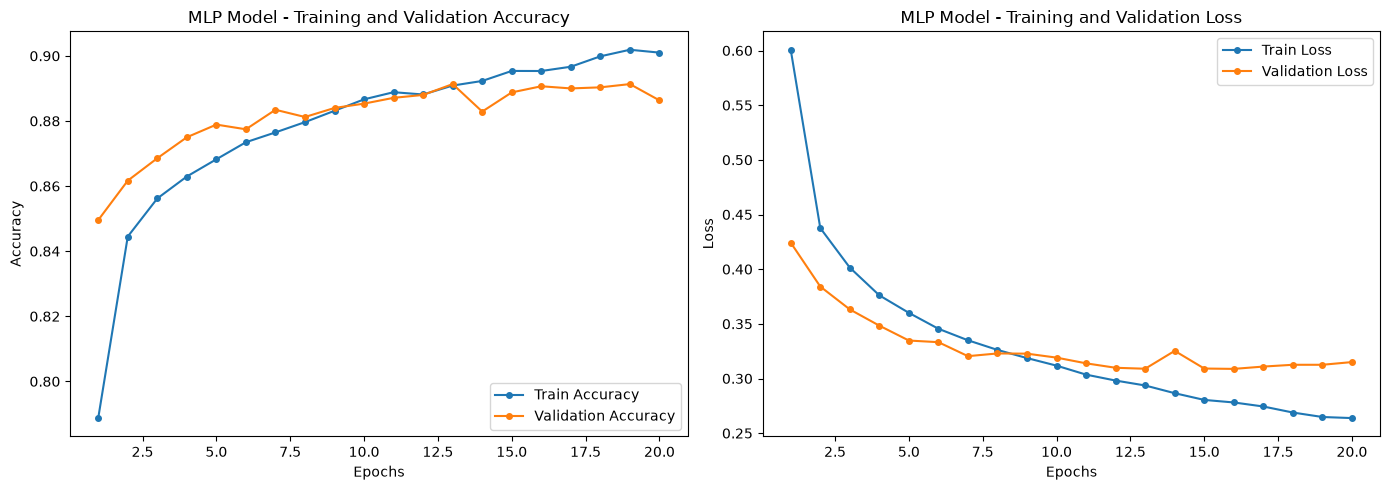

Final MLP Metrics (Epoch 20)Train Loss: 0.2638 | Val Loss: 0.3150 | Train Acc: 0.9010 | Val Acc: 0.8863


In [58]:
# Training the MLP model

history_mlp = mlp_model.fit(
    X_train_mlp,
    y_train,
    epochs=20,
    batch_size=64,
    validation_data=(X_val_mlp, y_val),
    verbose=1
)

# Extract metrics from training history
acc = history_mlp.history["accuracy"]
val_acc = history_mlp.history["val_accuracy"]
loss = history_mlp.history["loss"]
val_loss = history_mlp.history["val_loss"]
epochs_range = range(1, len(acc) + 1)

# Side-by-side subplots for Accuracy and Loss
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy curve
axes[0].plot(epochs_range, acc, label="Train Accuracy", marker="o", markersize=4)
axes[0].plot(epochs_range, val_acc, label="Validation Accuracy", marker="o", markersize=4)
axes[0].set_title("MLP Model - Training and Validation Accuracy")
axes[0].set_xlabel("Epochs")
axes[0].set_ylabel("Accuracy")
axes[0].legend(loc="lower right")

# Loss curve
axes[1].plot(epochs_range, loss, label="Train Loss", marker="o", markersize=4)
axes[1].plot(epochs_range, val_loss, label="Validation Loss", marker="o", markersize=4)
axes[1].set_title("MLP Model - Training and Validation Loss")
axes[1].set_xlabel("Epochs")
axes[1].set_ylabel("Loss")
axes[1].legend(loc="upper right")

plt.tight_layout()
plt.show()

print(
    f"Final MLP Metrics (Epoch {len(loss)})"
    f"Train Loss: {loss[-1]:.4f} | Val Loss: {val_loss[-1]:.4f} | "
    f"Train Acc: {acc[-1]:.4f} | Val Acc: {val_acc[-1]:.4f}"
)

MLP Test Loss:     0.3203
MLP Test Accuracy: 0.8874

MLP Classification Report:
              precision    recall  f1-score   support

 T-shirt/top       0.82      0.85      0.83      1000
     Trouser       0.99      0.97      0.98      1000
    Pullover       0.88      0.76      0.81      1000
       Dress       0.90      0.91      0.90      1000
        Coat       0.79      0.86      0.82      1000
      Sandal       0.99      0.93      0.96      1000
       Shirt       0.70      0.71      0.70      1000
     Sneaker       0.91      0.96      0.94      1000
         Bag       0.97      0.97      0.97      1000
  Ankle boot       0.95      0.95      0.95      1000

    accuracy                           0.89     10000


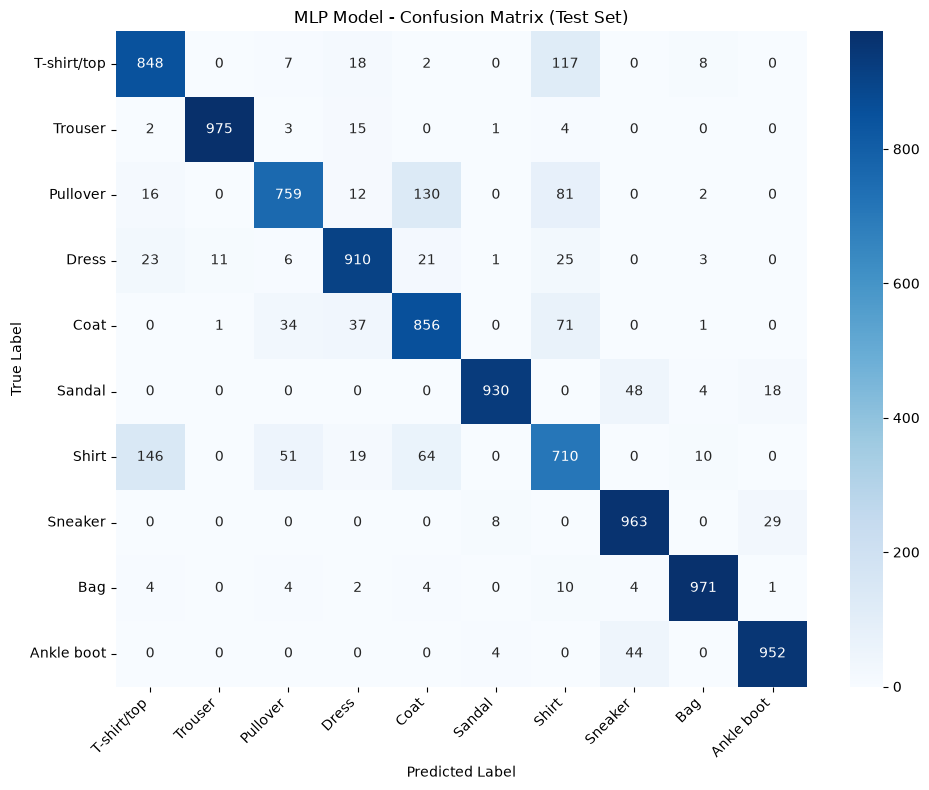

In [59]:
# Class names for Fashion-MNIST (indices 0 to 9)
class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

# Evaluate overall performance on the unseen test set
test_loss_mlp, test_acc_mlp = mlp_model.evaluate(X_test_mlp, y_test, verbose=0)
print(f"MLP Test Loss:     {test_loss_mlp:.4f}")
print(f"MLP Test Accuracy: {test_acc_mlp:.4f}\n")

# Generate class predictions (probabilities -> predicted class index)
y_pred_probs_mlp = mlp_model.predict(X_test_mlp, verbose=0)
y_pred_mlp = np.argmax(y_pred_probs_mlp, axis=1)

# Print detailed classification report per category (excluding 'macro avg' and 'weighted avg')
report_mlp = classification_report(y_test, y_pred_mlp, target_names=class_names)
clean_report_mlp = "\n".join(
    line for line in report_mlp.splitlines()
    if not any(avg in line for avg in ("macro avg", "weighted avg"))
)

print("MLP Classification Report:")
print(clean_report_mlp)

# Compute and plot the Confusion Matrix
cm_mlp = confusion_matrix(y_test, y_pred_mlp)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm_mlp,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title("MLP Model - Confusion Matrix (Test Set)")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Implementation (CNN)

In [60]:
# Reshape normalized datasets into 4D tensors (samples, 28, 28, 1) for CNN
X_train_cnn = X_train_mlp.reshape(-1, 28, 28, 1)
X_val_cnn = X_val_mlp.reshape(-1, 28, 28, 1)
X_test_cnn = X_test_mlp.reshape(-1, 28, 28, 1)

# Build the CNN architecture
cnn_model = Sequential([
    Input(shape=(28, 28, 1)), # 2D grayscale image input
    
    # First convolutional block: extracts basic edges and textures
    Conv2D(32, kernel_size=(3, 3), activation="relu", padding="same"),
    MaxPooling2D(pool_size=(2, 2)), # Downsamples spatial dimensions to 14x14
    
    # Second convolutional block: combines edges into higher-level garment features
    Conv2D(64, kernel_size=(3, 3), activation="relu", padding="same"),
    MaxPooling2D(pool_size=(2, 2)), # Downsamples spatial dimensions to 7x7
    
    # Classification head
    Flatten(), # Flattens 7x7x64 feature maps into a 3,136-element vector
    Dense(128, activation="relu"),
    Dropout(0.3), # Regularization to prevent overfitting
    Dense(10, activation="softmax") # Output class probabilities
], name="CNN_FashionMNIST")

# Compile the model
cnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

cnn_model.summary()

Model: "CNN_FashionMNIST"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 421,642 (1.61 MB)

 Trainable params: 421,642 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

In [61]:
# Train the CNN model for 20 epochs under the same conditions as the MLP
history_cnn = cnn_model.fit(
    X_train_cnn,
    y_train,
    epochs=20,
    batch_size=64,
    validation_data=(X_val_cnn, y_val),
    verbose=1
)

Epoch 1/20
797/797 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.8136 - loss: 0.5225 - val_accuracy: 0.8802 - val_loss: 0.3376
Epoch 2/20
797/797 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8761 - loss: 0.3443 - val_accuracy: 0.8982 - val_loss: 0.2913
Epoch 3/20
797/797 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8933 - loss: 0.2965 - val_accuracy: 0.9090 - val_loss: 0.2635
Epoch 4/20
797/797 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9069 - loss: 0.2614 - val_accuracy: 0.9112 - val_loss: 0.2527
Epoch 5/20
797/797 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9145 - loss: 0.2374 - val_accuracy: 0.9130 - val_loss: 0.2445
Epoch 6/20
797/797 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9218 - loss: 0.2131 - val_accuracy: 0.9144 - val_loss: 0.2366
Epoch 7/20
797/797 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9276 - loss: 0.1951 - val_accuracy: 0.9146 - val_loss: 0.2390
Epoch 8/20
797/797 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9330 - loss: 0.1805 - val_accuracy: 0.

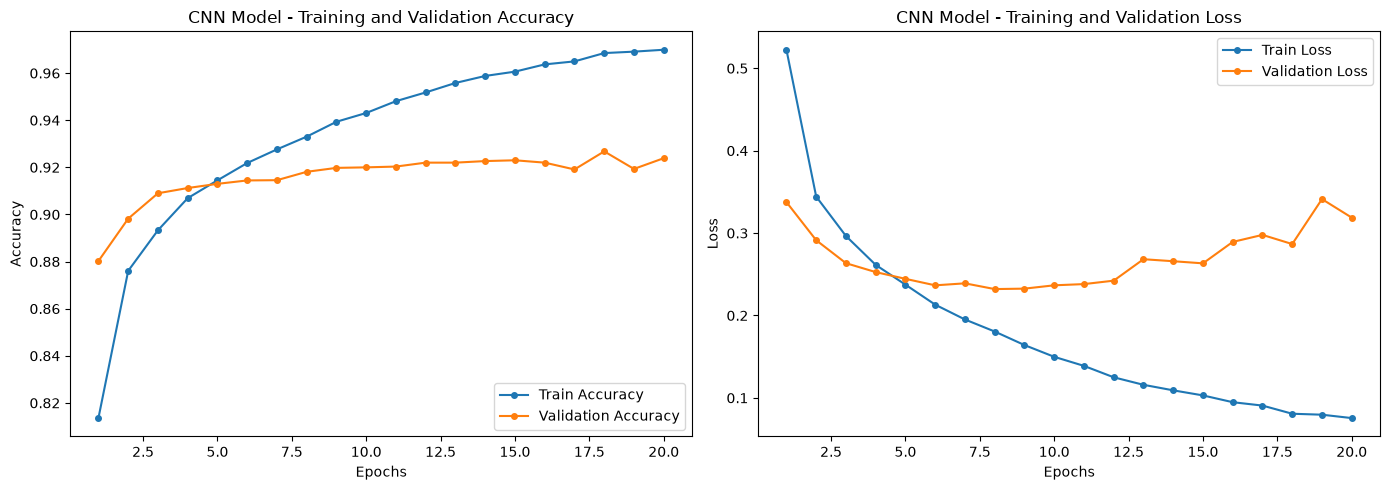

Final CNN Metrics (Epoch 20) -> Train Loss: 0.0755 | Val Loss: 0.3188 | Train Acc: 0.9699 | Val Acc: 0.9239


In [62]:

# Extract metrics from training history
acc_cnn = history_cnn.history["accuracy"]
val_acc_cnn = history_cnn.history["val_accuracy"]
loss_cnn = history_cnn.history["loss"]
val_loss_cnn = history_cnn.history["val_loss"]
epochs_range = range(1, len(acc_cnn) + 1)

# Create side-by-side subplots (without background grid)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Accuracy curve
axes[0].plot(epochs_range, acc_cnn, label="Train Accuracy", marker="o", markersize=4)
axes[0].plot(epochs_range, val_acc_cnn, label="Validation Accuracy", marker="o", markersize=4)
axes[0].set_title("CNN Model - Training and Validation Accuracy")
axes[0].set_xlabel("Epochs")
axes[0].set_ylabel("Accuracy")
axes[0].legend(loc="lower right")

# 2. Loss curve
axes[1].plot(epochs_range, loss_cnn, label="Train Loss", marker="o", markersize=4)
axes[1].plot(epochs_range, val_loss_cnn, label="Validation Loss", marker="o", markersize=4)
axes[1].set_title("CNN Model - Training and Validation Loss")
axes[1].set_xlabel("Epochs")
axes[1].set_ylabel("Loss")
axes[1].legend(loc="upper right")

plt.tight_layout()
plt.show()

# Print final epoch metrics in a single line
print(
    f"Final CNN Metrics (Epoch {len(loss_cnn)}) -> "
    f"Train Loss: {loss_cnn[-1]:.4f} | Val Loss: {val_loss_cnn[-1]:.4f} | "
    f"Train Acc: {acc_cnn[-1]:.4f} | Val Acc: {val_acc_cnn[-1]:.4f}"
)

CNN Test Loss:     0.3071
CNN Test Accuracy: 0.9242

CNN Classification Report:
              precision    recall  f1-score   support

 T-shirt/top       0.86      0.88      0.87      1000
     Trouser       0.99      0.99      0.99      1000
    Pullover       0.93      0.84      0.88      1000
       Dress       0.92      0.94      0.93      1000
        Coat       0.85      0.92      0.88      1000
      Sandal       0.99      0.97      0.98      1000
       Shirt       0.80      0.78      0.79      1000
     Sneaker       0.95      0.97      0.96      1000
         Bag       0.99      0.99      0.99      1000
  Ankle boot       0.96      0.97      0.97      1000

    accuracy                           0.92     10000


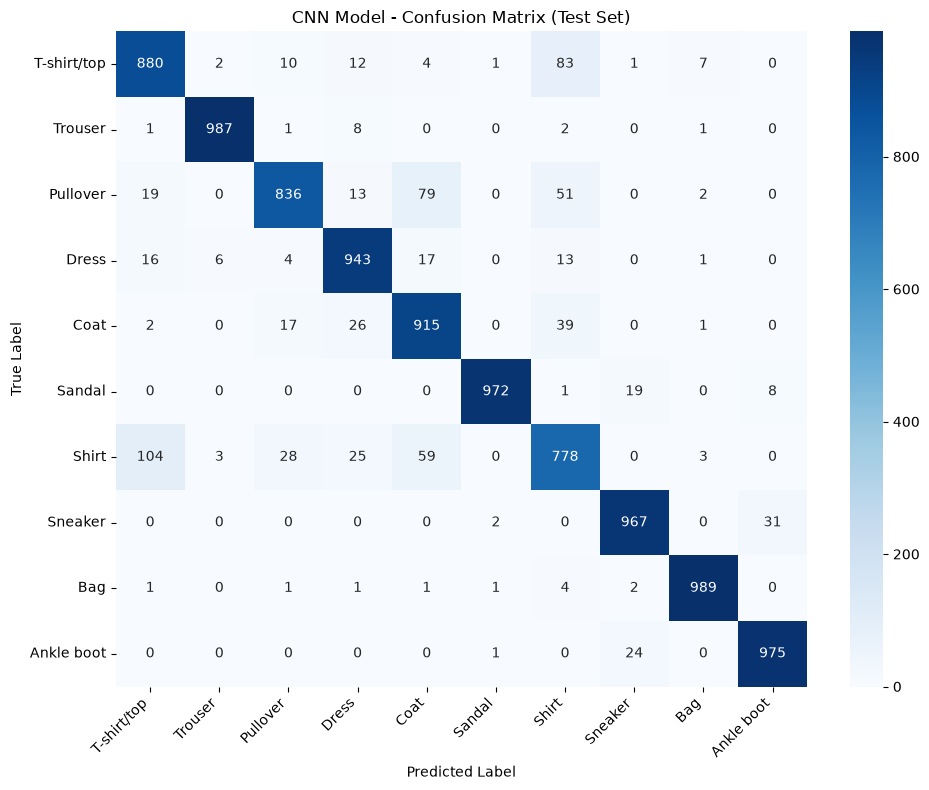

In [ ]:
# Class names for Fashion-MNIST (indices 0 to 9)
class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

# Evaluate overall performance on the unseen test set
test_loss_cnn, test_acc_cnn = cnn_model.evaluate(X_test_cnn, y_test, verbose=0)
print(f"CNN Test Loss:     {test_loss_cnn:.4f}")
print(f"CNN Test Accuracy: {test_acc_cnn:.4f}\n")

# Generate class predictions
y_pred_probs_cnn = cnn_model.predict(X_test_cnn, verbose=0)
y_pred_cnn = np.argmax(y_pred_probs_cnn, axis=1)

# Print detailed classification report (excluding 'macro avg' and 'weighted avg')
report_cnn = classification_report(y_test, y_pred_cnn, target_names=class_names)
clean_report_cnn = "\n".join(
    line for line in report_cnn.splitlines()
    if not any(avg in line for avg in ("macro avg", "weighted avg"))
)

print("CNN Classification Report:")
print(clean_report_cnn)

# Compute and plot the Confusion Matrix
cm_cnn = confusion_matrix(y_test, y_pred_cnn)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm_cnn,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title("CNN Model - Confusion Matrix (Test Set)")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()